
# 07 — Understanding BTL and CDM Through Interactions and Cyclic Preferences

**M.Tech Thesis — Learning Preference Models from Choice Data**

## Objective

The purpose of this notebook is to develop a mathematical and
computational understanding of the Context-Dependent Model (CDM),
with particular emphasis on its relationship to the
Bradley–Terry–Luce (BTL) model.

We begin with three alternatives, $A$, $B$, and $C$, and investigate
how pairwise interaction parameters determine choice probabilities.

Our central questions are:

1. What does the interaction parameter $u_{xz}$ represent?
2. How are CDM utilities constructed from the interaction matrix?
3. How do the pairwise choice probabilities under CDM compare
   with those under BTL?
4. Why can CDM represent cyclic preferences while BTL cannot?
5. How does the identifiability constraint affect the parameters?
6. Under what parameterization does CDM recover BTL?
7. What motivates a low-rank representation of the interaction matrix?

## Approach

We follow a progressive approach:

- **Mathematical derivation:** Establish the relevant equations.
- **Numerical illustration:** Work with three alternatives.
- **Computational verification:** Check mathematical identities
  using Python.
- **Visualization:** Present interaction matrices and choice
  probabilities using clearly labeled figures.
- **Interpretation:** Summarize what each result tells us
  about the models.

We use existing implementations from the project's `src/`
directory wherever appropriate.

## Scope

This notebook focuses on understanding the model structure
and its expressive capabilities.

Parameter estimation, maximum likelihood optimization,
large-scale synthetic experiments, and statistical recovery
analysis are outside the scope of this notebook.

## Expected Outcomes

By the end of this notebook, we should be able to:

- Interpret the entries of the CDM interaction matrix.
- Compute CDM choice probabilities for arbitrary choice sets.
- Explain the mathematical difference between BTL and CDM.
- Construct a cyclic preference example using CDM.
- Demonstrate the limitations of BTL in representing such cycles.
- Verify that BTL is contained within the CDM family.
- Identify the motivation for studying low-rank CDM.


In [1]:


# Cell 1 — Project setup and source-code inspection

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "pyproject.toml").exists()
        and (path / "src").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root containing "
        "pyproject.toml and src/."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEED = 20260831
RNG = np.random.default_rng(SEED)

ITEMS = ("A", "B", "C")
N_ITEMS = len(ITEMS)

np.set_printoptions(precision=4, suppress=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Items: {ITEMS}")
print(f"Seed: {SEED}")

for module_dir in (
    PROJECT_ROOT / "src" / "bradley_terry",
    PROJECT_ROOT / "src" / "context_dependent_model",
):
    print(f"\n{module_dir.relative_to(PROJECT_ROOT)}/")

    if not module_dir.exists():
        print("  Directory not found")
        continue

    for file in sorted(module_dir.rglob("*.py")):
        if "__pycache__" not in file.parts:
            print(f"  {file.relative_to(PROJECT_ROOT)}")


Project root: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-
Items: ('A', 'B', 'C')
Seed: 20260831

src/bradley_terry/
  src/bradley_terry/__init__.py
  src/bradley_terry/choix_estimation.py
  src/bradley_terry/diagnostics.py
  src/bradley_terry/estimation.py
  src/bradley_terry/experiments.py
  src/bradley_terry/metrics.py
  src/bradley_terry/model.py
  src/bradley_terry/optimization.py
  src/bradley_terry/pytorch_optimization.py
  src/bradley_terry/sampling.py
  src/bradley_terry/simulation.py

src/context_dependent_model/
  src/context_dependent_model/__init__.py
  src/context_dependent_model/estimation.py
  src/context_dependent_model/experiments.py
  src/context_dependent_model/metrics.py
  src/context_dependent_model/model.py
  src/context_dependent_model/sampling.py
  src/context_dependent_model/simulation.py


In [2]:

# Cell 2 — Inspect available model functions and signatures

import ast

SOURCE_FILES = [
    PROJECT_ROOT / "src/bradley_terry/model.py",
    PROJECT_ROOT / "src/context_dependent_model/model.py",
]

for file_path in SOURCE_FILES:
    print(f"\n{'=' * 65}")
    print(file_path.relative_to(PROJECT_ROOT))
    print("=" * 65)

    if not file_path.exists():
        print("File not found.")
        continue

    tree = ast.parse(file_path.read_text(encoding="utf-8"))

    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print(f"\nFunction: {node.name}")
            print(f"Signature: {ast.unparse(node.args)}")

        elif isinstance(node, ast.ClassDef):
            print(f"\nClass: {node.name}")

            for method in node.body:
                if isinstance(method, (ast.FunctionDef, ast.AsyncFunctionDef)):
                    if not method.name.startswith("_"):
                        print(f"  Method: {method.name}")
                        print(f"  Signature: {ast.unparse(method.args)}")



src/bradley_terry/model.py

Function: _as_parameter_array
Signature: parameters

Function: _as_comparison_array
Signature: comparisons, number_of_items

Function: sigmoid
Signature: value

Function: center_parameters
Signature: parameters

Function: bradley_terry_probability
Signature: item_i, item_j, parameters

Function: average_negative_log_likelihood
Signature: parameters, comparisons

Function: average_negative_log_likelihood_gradient
Signature: parameters, comparisons

src/context_dependent_model/model.py

Function: center_cdm_parameters
Signature: interaction_matrix: torch.Tensor

Function: cdm_choice_utilities
Signature: interaction_matrix: torch.Tensor, choice_sets: torch.Tensor, choice_mask: torch.Tensor | None=None

Function: cdm_choice_probabilities
Signature: interaction_matrix: torch.Tensor, choice_sets: torch.Tensor, choice_mask: torch.Tensor | None=None

Function: average_cdm_negative_log_likelihood
Signature: interaction_matrix: torch.Tensor, choice_sets: torch.Tensor


---

## Part 1 — Reparameterization and the Interaction Matrix

### 1.1 From the original utility to the reparameterized utility

Consider a choice set $C$ and an alternative $x\in C$.

The second-order utility is defined as

$$
v(x\mid C)
=
v(x)
+
\sum_{z\in C\setminus\{x\}}v(x\mid\{z\}).
$$

We introduce the interaction parameter

$$
\boxed{
u_{xz}=v(x\mid\{z\})-v(z),\qquad x\neq z.
}
$$

Rearranging,

$$
v(x\mid\{z\})=u_{xz}+v(z).
$$

Substituting this expression into the original utility,

$$
\begin{aligned}
v(x\mid C)
&=v(x)+\sum_{z\in C\setminus\{x\}}v(x\mid\{z\})\\[6pt]
&=v(x)+\sum_{z\in C\setminus\{x\}}u_{xz}
+\sum_{z\in C\setminus\{x\}}v(z)\\[6pt]
&=\underbrace{
v(x)+\sum_{z\in C\setminus\{x\}}v(z)
}_{\displaystyle\sum_{z\in C}v(z)}
+\sum_{z\in C\setminus\{x\}}u_{xz}\\[6pt]
&=\sum_{z\in C}v(z)
+\sum_{z\in C\setminus\{x\}}u_{xz}.
\end{aligned}
$$

The first term is identical for every alternative in the
same choice set. Therefore, it cancels from the softmax
choice probabilities.

We obtain the equivalent utility representation

$$
\boxed{
\widetilde{u}(x\mid C)
=
\sum_{z\in C\setminus\{x\}}u_{xz}.
}
$$

The original and reparameterized utilities need not be
numerically equal, but they produce identical choice
probabilities.

### Interpretation

The parameter $u_{xz}$ represents the contribution
associated with the presence of alternative $z$ to the
reparameterized utility of alternative $x$.

- $x$ is the **target alternative**.
- $z$ is the **context alternative**.
- $u_{xz}$ and $u_{zx}$ are distinct parameters.

The interpretation of an individual interaction parameter
must be understood relative to the model's parameterization
and identifiability convention.



### 1.2 Constructing the interaction matrix

For three alternatives,

$$
C=\{A,B,C\},
$$

the interaction matrix is

$$
U=
\begin{bmatrix}
0 & u_{AB} & u_{AC}\\
u_{BA} & 0 & u_{BC}\\
u_{CA} & u_{CB} & 0
\end{bmatrix}.
$$

Rows represent target alternatives, while columns represent
context alternatives.

The diagonal is zero because an alternative does not
interact with itself in the CDM utility formulation.

For the choice set $\{A,B,C\}$,

$$
\begin{aligned}
\widetilde{u}(A\mid\{A,B,C\}) &= u_{AB}+u_{AC},\\
\widetilde{u}(B\mid\{A,B,C\}) &= u_{BA}+u_{BC},\\
\widetilde{u}(C\mid\{A,B,C\}) &= u_{CA}+u_{CB}.
\end{aligned}
$$

For the smaller choice set $\{A,B\}$,

$$
\widetilde{u}(A\mid\{A,B\})=u_{AB},
\qquad
\widetilde{u}(B\mid\{A,B\})=u_{BA}.
$$

**Key observation:** The utility of an alternative depends
on which other alternatives are present in the choice set.


In [3]:

# Cell 5 — Construct a three-item CDM interaction matrix

import torch

from context_dependent_model.model import (
    center_cdm_parameters,
    cdm_choice_utilities,
    cdm_choice_probabilities,
)

DTYPE = torch.float64

# Rows: target items; columns: context items.
U_raw = torch.tensor(
    [
        [0.0,  1.0,  0.5],   # Target A
        [-0.5, 0.0,  0.8],   # Target B
        [0.2, -0.4,  0.0],   # Target C
    ],
    dtype=DTYPE,
)

# Apply the existing CDM centering convention.
U = center_cdm_parameters(U_raw)

interaction_table = pd.DataFrame(
    U.detach().numpy(),
    index=ITEMS,
    columns=ITEMS,
)

print("CDM interaction matrix:")
display(interaction_table.round(4))

print(f"Sum of interaction parameters: {U.sum().item():.8f}")
print(f"Diagonal entries: {torch.diag(U).tolist()}")

assert torch.allclose(
    torch.diag(U),
    torch.zeros(N_ITEMS, dtype=DTYPE),
)

assert torch.isclose(
    U.sum(),
    torch.tensor(0.0, dtype=DTYPE),
    atol=1e-10,
)


CDM interaction matrix:


,A,B,C
A,-0.0000,0.7333,0.2333
B,-0.7667,-0.0000,0.5333
C,-0.0667,-0.6667,-0.0000


Sum of interaction parameters: 0.00000000
Diagonal entries: [-0.0, -0.0, -0.0]


In [4]:

# Cell 6 — Verify CDM utilities for different choice sets

# Each row contains one choice set.
choice_sets = torch.tensor(
    [
        [0, 1, 2],  # {A, B, C}
        [0, 1, 0],  # {A, B}; final entry is padding
    ],
    dtype=torch.long,
)

choice_mask = torch.tensor(
    [
        [True, True, True],
        [True, True, False],
    ],
    dtype=torch.bool,
)

utilities = cdm_choice_utilities(
    interaction_matrix=U,
    choice_sets=choice_sets,
    choice_mask=choice_mask,
)

print("Utilities returned by src/context_dependent_model/model.py:")
print(utilities)

# Verify the three-item choice set manually.
expected_abc = torch.tensor(
    [
        U[0, 1] + U[0, 2],
        U[1, 0] + U[1, 2],
        U[2, 0] + U[2, 1],
    ],
    dtype=DTYPE,
)

assert torch.allclose(utilities[0], expected_abc)

# Verify the two-item choice set.
assert torch.allclose(
    utilities[1, :2],
    torch.stack([U[0, 1], U[1, 0]]),
)

print("\nBoth utility calculations match the manual equations.")


Utilities returned by src/context_dependent_model/model.py:
tensor([[ 0.9667, -0.2333, -0.7333],
        [ 0.7333, -0.7667,    -inf]], dtype=torch.float64)

Both utility calculations match the manual equations.



---

## Part 2 — Pairwise Choice Probabilities Under CDM

### 2.1 From interaction parameters to choice probabilities

Consider two alternatives, $A$ and $B$, with the choice set

$$
C=\{A,B\}.
$$

Under the reparameterized CDM, their utilities are

$$
\widetilde{u}(A\mid C)=u_{AB},
\qquad
\widetilde{u}(B\mid C)=u_{BA}.
$$

Using the softmax choice rule,

$$
P(A\mid\{A,B\})
=
\frac{\exp(u_{AB})}
{\exp(u_{AB})+\exp(u_{BA})}.
$$

Dividing the numerator and denominator by $\exp(u_{AB})$,

$$
P(A\mid\{A,B\})
=
\frac{1}{1+\exp(u_{BA}-u_{AB})}.
$$

Recall that the sigmoid function is

$$
\sigma(t)=\frac{1}{1+\exp(-t)}.
$$

Therefore,

$$
\boxed{
P(A\mid\{A,B\})=\sigma(u_{AB}-u_{BA}).
}
$$

Similarly,

$$
\boxed{
P(B\mid\{B,C\})=\sigma(u_{BC}-u_{CB})
}
$$

and

$$
\boxed{
P(C\mid\{C,A\})=\sigma(u_{CA}-u_{AC}).
}
$$

### Key observation

For a pairwise choice, the probability depends on the
**difference between two directed interaction parameters**.

For example, $u_{AB}$ and $u_{BA}$ need not be equal.

A positive value of $u_{AB}-u_{BA}$ implies

$$
P(A\mid\{A,B\})>0.5.
$$

This formulation will allow us to compare CDM with BTL
and investigate cyclic preferences.


In [5]:

# Cell 8 — Verify pairwise CDM probabilities using softmax and sigmoid

from bradley_terry.model import sigmoid

PAIR_INDICES = [(0, 1), (1, 2), (2, 0)]
PAIR_NAMES = ["A vs B", "B vs C", "C vs A"]

pair_choice_sets = torch.tensor(
    PAIR_INDICES,
    dtype=torch.long,
)

# Probabilities computed by the existing CDM implementation.
pair_probabilities = cdm_choice_probabilities(
    interaction_matrix=U,
    choice_sets=pair_choice_sets,
)

rows = []

for pair_name, (i, j), probabilities in zip(
    PAIR_NAMES, PAIR_INDICES, pair_probabilities
):
    interaction_difference = (U[i, j] - U[j, i]).item()

    probability_sigmoid = float(
        np.asarray(sigmoid(interaction_difference))
    )

    probability_cdm = probabilities[0].item()

    rows.append(
        {
            "Pair": pair_name,
            "Interaction difference": interaction_difference,
            "Sigmoid probability": probability_sigmoid,
            "CDM probability": probability_cdm,
            "Absolute difference": abs(
                probability_sigmoid - probability_cdm
            ),
        }
    )

pairwise_results = pd.DataFrame(rows)

display(pairwise_results.round(6))

assert np.allclose(
    pairwise_results["Sigmoid probability"],
    pairwise_results["CDM probability"],
    atol=1e-10,
)

assert torch.allclose(
    pair_probabilities.sum(dim=1),
    torch.ones(3, dtype=DTYPE),
)

print("Verified: sigmoid and CDM softmax probabilities agree.")


,Pair,Interaction difference,Sigmoid probability,CDM probability,Absolute difference
0,A vs B,1.5,0.817574,0.817574,0.0
1,B vs C,1.2,0.768525,0.768525,0.0
2,C vs A,-0.3,0.425557,0.425557,0.0


Verified: sigmoid and CDM softmax probabilities agree.


In [6]:

# Cell 8 — Verify pairwise CDM probabilities using softmax and sigmoid

from bradley_terry.model import sigmoid

PAIR_INDICES = [(0, 1), (1, 2), (2, 0)]
PAIR_NAMES = ["A vs B", "B vs C", "C vs A"]

pair_choice_sets = torch.tensor(
    PAIR_INDICES,
    dtype=torch.long,
)

# Probabilities computed by the existing CDM implementation.
pair_probabilities = cdm_choice_probabilities(
    interaction_matrix=U,
    choice_sets=pair_choice_sets,
)

rows = []

for pair_name, (i, j), probabilities in zip(
    PAIR_NAMES, PAIR_INDICES, pair_probabilities
):
    interaction_difference = (U[i, j] - U[j, i]).item()

    probability_sigmoid = float(
        np.asarray(sigmoid(interaction_difference))
    )

    probability_cdm = probabilities[0].item()

    rows.append(
        {
            "Pair": pair_name,
            "Interaction difference": interaction_difference,
            "Sigmoid probability": probability_sigmoid,
            "CDM probability": probability_cdm,
            "Absolute difference": abs(
                probability_sigmoid - probability_cdm
            ),
        }
    )

pairwise_results = pd.DataFrame(rows)

display(pairwise_results.round(6))

assert np.allclose(
    pairwise_results["Sigmoid probability"],
    pairwise_results["CDM probability"],
    atol=1e-10,
)

assert torch.allclose(
    pair_probabilities.sum(dim=1),
    torch.ones(3, dtype=DTYPE),
)

print("Verified: sigmoid and CDM softmax probabilities agree.")


,Pair,Interaction difference,Sigmoid probability,CDM probability,Absolute difference
0,A vs B,1.5,0.817574,0.817574,0.0
1,B vs C,1.2,0.768525,0.768525,0.0
2,C vs A,-0.3,0.425557,0.425557,0.0


Verified: sigmoid and CDM softmax probabilities agree.


In [8]:

# Cell 10 — Compare BTL and CDM pairwise choice probabilities

from bradley_terry.model import (
    bradley_terry_probability,
    center_parameters,
)

theta = center_parameters(
    np.array([1.0, 0.0, -1.0], dtype=np.float64)
)

comparison_rows = []

for pair_name, (i, j), cdm_probs in zip(
    PAIR_NAMES, PAIR_INDICES, pair_probabilities
):
    p_btl = float(
        bradley_terry_probability(i, j, theta)
    )

    p_cdm = float(cdm_probs[0].item())

    comparison_rows.append(
        {
            "Pair": pair_name,
            "BTL probability": p_btl,
            "CDM probability": p_cdm,
            "Difference (CDM - BTL)": p_cdm - p_btl,
        }
    )

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df.round(6))

# Verify the BTL pairwise log-odds constraint.
btl_log_odds = [
    theta[i] - theta[j]
    for i, j in PAIR_INDICES
]

assert np.isclose(sum(btl_log_odds), 0.0)

print("BTL pairwise log-odds:", btl_log_odds)
print("Sum of BTL pairwise log-odds:", sum(btl_log_odds))


,Pair,BTL probability,CDM probability,Difference (CDM - BTL)
0,A vs B,0.731059,0.817574,0.086516
1,B vs C,0.731059,0.768525,0.037466
2,C vs A,0.119203,0.425557,0.306355


BTL pairwise log-odds: [np.float64(1.0), np.float64(1.0), np.float64(-2.0)]
Sum of BTL pairwise log-odds: 0.0


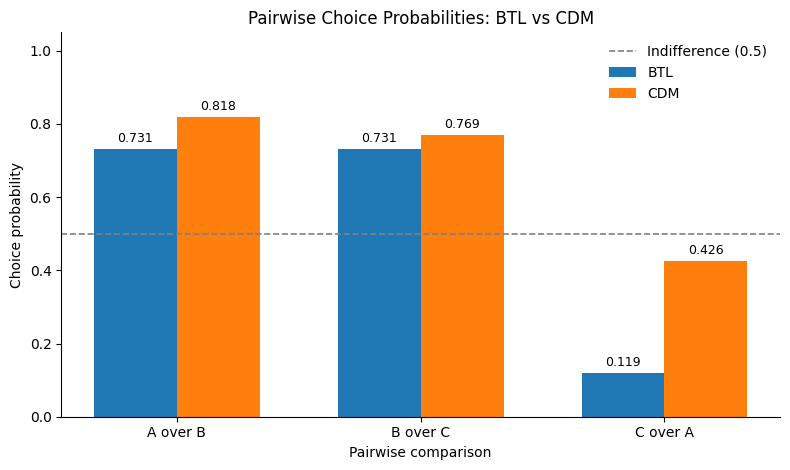

Figure saved to: docs/thesis/images/experiments/context_dependent_model/foundations/btl_vs_cdm_pairwise_probabilities.png


In [9]:

# Cell 11 — Visualize BTL and CDM pairwise probabilities

FIGURE_DIR = (
    PROJECT_ROOT
    / "docs/thesis/images/experiments"
    / "context_dependent_model/foundations"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

labels = ["A over B", "B over C", "C over A"]
x_positions = np.arange(len(labels))
bar_width = 0.34

fig, ax = plt.subplots(figsize=(8, 4.8))

bars_btl = ax.bar(
    x_positions - bar_width / 2,
    comparison_df["BTL probability"],
    bar_width,
    label="BTL",
)

bars_cdm = ax.bar(
    x_positions + bar_width / 2,
    comparison_df["CDM probability"],
    bar_width,
    label="CDM",
)

ax.axhline(
    0.5,
    linestyle="--",
    linewidth=1.2,
    color="gray",
    label="Indifference (0.5)",
)

ax.set_xticks(x_positions, labels)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Choice probability")
ax.set_xlabel("Pairwise comparison")
ax.set_title("Pairwise Choice Probabilities: BTL vs CDM")
ax.legend(frameon=False)

for bars in (bars_btl, bars_cdm):
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

figure_path = FIGURE_DIR / "btl_vs_cdm_pairwise_probabilities.png"

fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {figure_path.relative_to(PROJECT_ROOT)}")



---

## Part 4 — Cyclic Preferences and Model Expressiveness

### 4.1 What is a cyclic preference?

Consider three alternatives, $A$, $B$, and $C$.

A cyclic preference occurs when the pairwise majority
preferences satisfy

$$
\boxed{
A\succ B,\qquad B\succ C,\qquad C\succ A.
}
$$

Equivalently,

$$
P(A\mid\{A,B\})>0.5,
$$

$$
P(B\mid\{B,C\})>0.5,
$$

$$
P(C\mid\{C,A\})>0.5.
$$

This produces a directed preference cycle:

$$
A\longrightarrow B\longrightarrow C\longrightarrow A.
$$

### 4.2 Why BTL cannot represent this cycle

Under BTL,

$$
P(A\mid\{A,B\})=\sigma(\theta_A-\theta_B).
$$

Since the sigmoid function is strictly increasing,

$$
P(A\mid\{A,B\})>0.5
\iff \theta_A>\theta_B.
$$

Similarly,

$$
P(B\mid\{B,C\})>0.5
\iff \theta_B>\theta_C,
$$

and

$$
P(C\mid\{C,A\})>0.5
\iff \theta_C>\theta_A.
$$

Combining these inequalities would require

$$
\theta_A>\theta_B>\theta_C>\theta_A,
$$

which is impossible.

Therefore, BTL cannot represent a strict cyclic
majority-preference pattern.

This limitation arises because BTL assigns a single
context-independent parameter to each alternative.

### 4.3 Why CDM can represent this cycle

Under CDM, the corresponding pairwise probabilities are

$$
\begin{aligned}
P(A\mid\{A,B\})&=\sigma(u_{AB}-u_{BA}),\\
P(B\mid\{B,C\})&=\sigma(u_{BC}-u_{CB}),\\
P(C\mid\{C,A\})&=\sigma(u_{CA}-u_{AC}).
\end{aligned}
$$

Unlike BTL, these three interaction differences are
not required to sum to zero.

Consequently, all three can be positive simultaneously,
allowing CDM to represent cyclic preferences.

We now construct and verify such an example.


In [10]:

# Cell 13 — Construct a CDM interaction matrix with cyclic preferences

U_cycle_raw = torch.tensor(
    [
        [ 0.0,  1.0, -1.0],
        [-1.0,  0.0,  1.0],
        [ 1.0, -1.0,  0.0],
    ],
    dtype=DTYPE,
)

U_cycle = center_cdm_parameters(U_cycle_raw)

cycle_matrix_df = pd.DataFrame(
    U_cycle.detach().numpy(),
    index=ITEMS,
    columns=ITEMS,
)

print("Cyclic CDM interaction matrix:")
display(cycle_matrix_df.round(4))

# Verify the zero-sum identifiability constraint.
assert torch.allclose(
    U_cycle.sum(),
    torch.tensor(0.0, dtype=DTYPE),
    atol=1e-10,
)

# Compute the three pairwise choice probabilities.
cycle_probabilities = cdm_choice_probabilities(
    interaction_matrix=U_cycle,
    choice_sets=pair_choice_sets,
)

cycle_rows = []

for pair_name, (i, j), probabilities in zip(
    PAIR_NAMES, PAIR_INDICES, cycle_probabilities
):
    cycle_rows.append(
        {
            "Pair": pair_name,
            "Interaction difference": (U_cycle[i, j] - U_cycle[j, i]).item(),
            "Winning probability": probabilities[0].item(),
        }
    )

cycle_df = pd.DataFrame(cycle_rows)

display(cycle_df.round(6))

assert (cycle_df["Winning probability"] > 0.5).all()

print("Verified: A beats B, B beats C, and C beats A.")


Cyclic CDM interaction matrix:


,A,B,C
A,0.0,1.0,-1.0
B,-1.0,0.0,1.0
C,1.0,-1.0,0.0


,Pair,Interaction difference,Winning probability
0,A vs B,2.0,0.880797
1,B vs C,2.0,0.880797
2,C vs A,2.0,0.880797


Verified: A beats B, B beats C, and C beats A.





### 4.4 Interpretation of the cyclic preference example

The constructed CDM interaction matrix satisfies

$$
u_{AB}-u_{BA}=2,
$$

$$
u_{BC}-u_{CB}=2,
$$

$$
u_{CA}-u_{AC}=2.
$$

Therefore,

$$
P(A\mid\{A,B\})
=
P(B\mid\{B,C\})
=
P(C\mid\{C,A\})
=
\sigma(2)
\approx 0.8808.
$$

All three pairwise majority preferences hold
simultaneously.

The corresponding BTL conditions would require

$$
\theta_A>\theta_B>\theta_C>\theta_A,
$$

which is impossible.

**Conclusion:** The CDM can represent cyclic pairwise
preferences that are excluded by the BTL model.

This illustrates the greater expressive flexibility
of CDM for pairwise choice data.


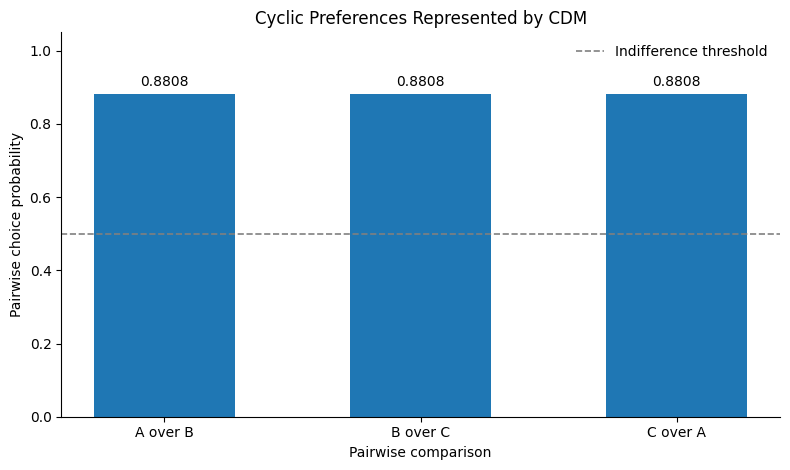

Figure saved to: docs/thesis/images/experiments/context_dependent_model/foundations/cdm_cyclic_preferences.png


In [11]:

# Cell 15 — Visualize cyclic preference probabilities

fig, ax = plt.subplots(figsize=(8, 4.8))

bars = ax.bar(
    ["A over B", "B over C", "C over A"],
    cycle_df["Winning probability"],
    width=0.55,
)

ax.axhline(
    0.5,
    color="gray",
    linestyle="--",
    linewidth=1.2,
    label="Indifference threshold",
)

ax.bar_label(bars, fmt="%.4f", padding=4)

ax.set_ylim(0, 1.05)
ax.set_ylabel("Pairwise choice probability")
ax.set_xlabel("Pairwise comparison")
ax.set_title("Cyclic Preferences Represented by CDM")

ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

cycle_figure_path = FIGURE_DIR / "cdm_cyclic_preferences.png"

fig.savefig(
    cycle_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Figure saved to: "
    f"{cycle_figure_path.relative_to(PROJECT_ROOT)}"
)


In [12]:

# Cell 16 — Compare pairwise and three-item choice behavior

triple_choice_set = torch.tensor(
    [[0, 1, 2]],
    dtype=torch.long,
)

triple_utilities = cdm_choice_utilities(
    interaction_matrix=U_cycle,
    choice_sets=triple_choice_set,
)

triple_probabilities = cdm_choice_probabilities(
    interaction_matrix=U_cycle,
    choice_sets=triple_choice_set,
)

triple_df = pd.DataFrame(
    {
        "Alternative": ITEMS,
        "Utility": triple_utilities[0].detach().numpy(),
        "Choice probability": triple_probabilities[0].detach().numpy(),
    }
)

display(triple_df.round(6))

assert torch.allclose(
    triple_probabilities[0],
    torch.full((3,), 1.0 / 3.0, dtype=DTYPE),
    atol=1e-10,
)

print("All three alternatives have probability 1/3 in the full choice set.")


,Alternative,Utility,Choice probability
0,A,0.0,0.333333
1,B,0.0,0.333333
2,C,0.0,0.333333


All three alternatives have probability 1/3 in the full choice set.



---

## Part 5 — Parameter Freedom and Identifiability

### 5.1 Number of parameters in BTL

For $n$ alternatives, the Bradley–Terry–Luce model
assigns one parameter $\theta_x$ to each alternative.

The parameter vector is

$$
\boldsymbol{\theta}
=
(\theta_1,\theta_2,\ldots,\theta_n).
$$

Because adding the same constant to every parameter
does not change the choice probabilities, we impose
the identifiability constraint

$$
\sum_{x=1}^{n}\theta_x=0.
$$

Therefore, BTL has

$$
\boxed{n-1}
$$

free parameters.

For $n=3$, this gives $2$ free parameters.

### 5.2 Number of parameters in CDM

In the full CDM, each ordered pair of distinct
alternatives has an interaction parameter $u_{xz}$.

The interaction matrix contains

$$
n(n-1)
$$

off-diagonal parameters.

A common identifiability constraint is

$$
\sum_{x\neq z}u_{xz}=0.
$$

This removes the global additive-shift ambiguity,
giving

$$
\boxed{n(n-1)-1}
$$

free parameters in the full parameterization.

For $n=3$,

$$
3(3-1)-1=5.
$$

Thus:

| Model | Raw parameters | Free parameters |
|---|---:|---:|
| BTL | 3 | 2 |
| Full CDM | 6 | 5 |

### 5.3 Parameter count versus identifiability from data

Having five free CDM parameters does not mean that
all five can be recovered from pairwise choices alone.

For three alternatives, pairwise observations determine
only the following three differences:

$$
d_{AB}=u_{AB}-u_{BA},
$$

$$
d_{BC}=u_{BC}-u_{CB},
$$

$$
d_{CA}=u_{CA}-u_{AC}.
$$

The individual interaction parameters are not
separately determined by these differences.

This distinction is important:

- **Parameter count** describes the dimension of the model.
- **Identifiability** concerns whether different parameter
  values can produce the same observed choice probabilities.

We investigate this using a numerical example.


,Number of items,BTL free parameters,CDM free parameters
0,2,1,1
1,3,2,5
2,4,3,11
3,5,4,19
4,6,5,29
5,7,6,41
6,8,7,55
7,9,8,71
8,10,9,89
9,11,10,109


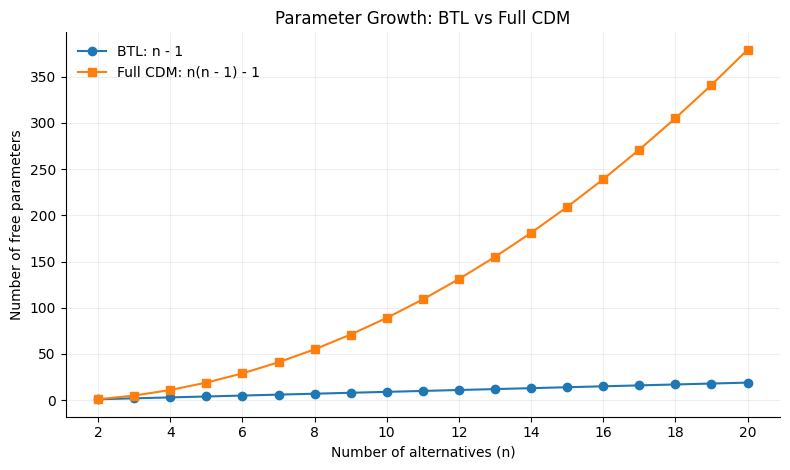

Saved: docs/thesis/images/experiments/context_dependent_model/foundations/btl_vs_cdm_parameter_growth.png


In [13]:

# Cell 18 — Compare BTL and full CDM parameter counts

item_counts = np.arange(2, 21)

parameter_counts = pd.DataFrame(
    {
        "Number of items": item_counts,
        "BTL free parameters": item_counts - 1,
        "CDM free parameters": item_counts * (item_counts - 1) - 1,
    }
)

display(parameter_counts)

fig, ax = plt.subplots(figsize=(8, 4.8))

ax.plot(
    item_counts,
    parameter_counts["BTL free parameters"],
    marker="o",
    label="BTL: n - 1",
)

ax.plot(
    item_counts,
    parameter_counts["CDM free parameters"],
    marker="s",
    label="Full CDM: n(n - 1) - 1",
)

ax.set_xlabel("Number of alternatives (n)")
ax.set_ylabel("Number of free parameters")
ax.set_title("Parameter Growth: BTL vs Full CDM")
ax.set_xticks(item_counts[::2])
ax.legend(frameon=False)
ax.grid(alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

parameter_figure_path = FIGURE_DIR / "btl_vs_cdm_parameter_growth.png"

fig.savefig(parameter_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {parameter_figure_path.relative_to(PROJECT_ROOT)}")



### 5.4 Can two different interaction matrices produce
the same pairwise probabilities?

Consider an interaction matrix $U$.

For a pair $\{A,B\}$, the choice probability depends on

$$
u_{AB}-u_{BA}.
$$

Suppose we add the same number $\delta$ to both entries:

$$
u'_{AB}=u_{AB}+\delta,
$$

$$
u'_{BA}=u_{BA}+\delta.
$$

Their difference remains unchanged:

$$
u'_{AB}-u'_{BA}
=
u_{AB}-u_{BA}.
$$

Therefore, the pairwise probability remains unchanged.

To preserve the global zero-sum constraint, we can
simultaneously subtract $\delta$ from both $u_{AC}$
and $u_{CA}$.

This transformation leaves all three pairwise
probabilities unchanged, but it can change the
probabilities when all three alternatives are offered.

We verify this using the existing CDM implementation.


In [14]:

# Cell 20 — Demonstrate non-identifiability from pairwise data alone

delta = 0.75

U_modified = U.clone()

# Add delta to both directions of the A-B interaction.
U_modified[0, 1] += delta
U_modified[1, 0] += delta

# Subtract delta from both directions of the A-C interaction.
U_modified[0, 2] -= delta
U_modified[2, 0] -= delta

assert torch.allclose(
    U_modified.sum(),
    torch.tensor(0.0, dtype=DTYPE),
    atol=1e-10,
)

assert not torch.allclose(U, U_modified)

original_pair_probs = cdm_choice_probabilities(
    interaction_matrix=U,
    choice_sets=pair_choice_sets,
)

modified_pair_probs = cdm_choice_probabilities(
    interaction_matrix=U_modified,
    choice_sets=pair_choice_sets,
)

original_triple_probs = cdm_choice_probabilities(
    interaction_matrix=U,
    choice_sets=triple_choice_set,
)

modified_triple_probs = cdm_choice_probabilities(
    interaction_matrix=U_modified,
    choice_sets=triple_choice_set,
)

pairwise_comparison = pd.DataFrame(
    {
        "Pair": PAIR_NAMES,
        "Original probability": original_pair_probs[:, 0].numpy(),
        "Modified probability": modified_pair_probs[:, 0].numpy(),
    }
)

triple_comparison = pd.DataFrame(
    {
        "Alternative": ITEMS,
        "Original probability": original_triple_probs[0].numpy(),
        "Modified probability": modified_triple_probs[0].numpy(),
    }
)

print("Pairwise choice probabilities:")
display(pairwise_comparison.round(6))

print("\nThree-item choice probabilities:")
display(triple_comparison.round(6))

assert torch.allclose(
    original_pair_probs,
    modified_pair_probs,
    atol=1e-10,
)

assert not torch.allclose(
    original_triple_probs,
    modified_triple_probs,
    atol=1e-10,
)

print("\nVerified:")
print("Different interaction matrices produce identical pairwise probabilities.")
print("However, their three-item choice probabilities differ.")


Pairwise choice probabilities:


,Pair,Original probability,Modified probability
0,A vs B,0.817574,0.817574
1,B vs C,0.768525,0.768525
2,C vs A,0.425557,0.425557



Three-item choice probabilities:


,Alternative,Original probability,Modified probability
0,A,0.673910,0.580073
1,B,0.202978,0.369871
2,C,0.123112,0.050057



Verified:
Different interaction matrices produce identical pairwise probabilities.
However, their three-item choice probabilities differ.



---

## Part 6 — Recovering BTL as a Special Case of CDM

### 6.1 Relationship between BTL and CDM

The Bradley–Terry–Luce (BTL) model assigns each
alternative $x$ an intrinsic parameter $\theta_x$.

Its choice probability for a choice set $C$ is

$$
P_{\mathrm{BTL}}(x\mid C)
=
\frac{\exp(\theta_x)}
{\sum_{y\in C}\exp(\theta_y)}.
$$

The reparameterized Context-Dependent Model (CDM)
defines the utility of alternative $x$ as

$$
\widetilde{u}(x\mid C)
=
\sum_{z\in C\setminus\{x\}}u_{xz}.
$$

We now construct a CDM interaction matrix using the
BTL parameters:

$$
\boxed{
u_{xz}=-\theta_z,\qquad x\neq z.
}
$$

Substituting into the CDM utility,

$$
\begin{aligned}
\widetilde{u}(x\mid C)
&=\sum_{z\in C\setminus\{x\}}(-\theta_z)\\[6pt]
&=-\sum_{z\in C\setminus\{x\}}\theta_z\\[6pt]
&=\theta_x-\sum_{z\in C}\theta_z.
\end{aligned}
$$

The second term is constant across all alternatives
in the same choice set.

Therefore, it cancels from the softmax probabilities:

$$
\begin{aligned}
P_{\mathrm{CDM}}(x\mid C)
&=
\frac{
\exp\left(\theta_x-\sum_{z\in C}\theta_z\right)
}{
\sum_{y\in C}
\exp\left(\theta_y-\sum_{z\in C}\theta_z\right)
}\\[6pt]
&=
\frac{\exp(\theta_x)}
{\sum_{y\in C}\exp(\theta_y)}\\[6pt]
&=P_{\mathrm{BTL}}(x\mid C).
\end{aligned}
$$

Hence,

$$
\boxed{
P_{\mathrm{CDM}}(x\mid C)
=
P_{\mathrm{BTL}}(x\mid C)
}
$$

for every nonempty choice set $C$.

### Interpretation

BTL is contained within the CDM model family.

Under this parameterization, the CDM interaction
parameters depend only on the context alternative $z$,
not on the target alternative $x$.

Consequently, the resulting choice probabilities
are equivalent to those of a context-independent BTL model.


In [15]:

# Cell 22 — Construct a CDM interaction matrix from BTL parameters

theta_torch = torch.as_tensor(
    theta,
    dtype=DTYPE,
)

U_from_btl = torch.zeros(
    (N_ITEMS, N_ITEMS),
    dtype=DTYPE,
)

for x in range(N_ITEMS):
    for z in range(N_ITEMS):
        if x != z:
            U_from_btl[x, z] = -theta_torch[z]

# Apply the existing CDM centering convention.
U_from_btl = center_cdm_parameters(U_from_btl)

btl_cdm_matrix_df = pd.DataFrame(
    U_from_btl.numpy(),
    index=ITEMS,
    columns=ITEMS,
)

print("CDM interaction matrix constructed from BTL:")
display(btl_cdm_matrix_df.round(4))

assert torch.allclose(
    torch.diag(U_from_btl),
    torch.zeros(N_ITEMS, dtype=DTYPE),
)

assert torch.isclose(
    U_from_btl.sum(),
    torch.tensor(0.0, dtype=DTYPE),
    atol=1e-10,
)

print("BTL-derived CDM matrix satisfies the centering constraint.")


CDM interaction matrix constructed from BTL:


,A,B,C
A,0.0,-0.0,1.0
B,-1.0,0.0,1.0
C,-1.0,-0.0,0.0


BTL-derived CDM matrix satisfies the centering constraint.


In [16]:

# Cell 23 — Verify BTL-CDM equivalence for every choice set

from itertools import combinations

choice_set_rows = []

for set_size in range(2, N_ITEMS + 1):
    for selected_items in combinations(range(N_ITEMS), set_size):

        selected = list(selected_items)

        # BTL softmax probabilities.
        selected_theta = theta_torch[selected]
        btl_probs = torch.softmax(selected_theta, dim=0)

        # CDM probabilities from the existing src implementation.
        selected_tensor = torch.tensor(
            [selected],
            dtype=torch.long,
        )

        cdm_probs = cdm_choice_probabilities(
            interaction_matrix=U_from_btl,
            choice_sets=selected_tensor,
        )[0]

        assert torch.allclose(
            btl_probs,
            cdm_probs,
            atol=1e-10,
        )

        for position, item_idx in enumerate(selected):
            choice_set_rows.append(
                {
                    "Choice set": "{" + ", ".join(ITEMS[i] for i in selected) + "}",
                    "Alternative": ITEMS[item_idx],
                    "BTL probability": btl_probs[position].item(),
                    "CDM probability": cdm_probs[position].item(),
                    "Absolute difference": abs(
                        btl_probs[position].item()
                        - cdm_probs[position].item()
                    ),
                }
            )

equivalence_df = pd.DataFrame(choice_set_rows)

display(equivalence_df.round(6))

print("Verified: BTL and CDM probabilities match for every tested choice set.")


,Choice set,Alternative,BTL probability,CDM probability,Absolute difference
0,"{A, B}",A,0.731059,0.731059,0.0
1,"{A, B}",B,0.268941,0.268941,0.0
2,"{A, C}",A,0.880797,0.880797,0.0
3,"{A, C}",C,0.119203,0.119203,0.0
4,"{B, C}",B,0.731059,0.731059,0.0
5,"{B, C}",C,0.268941,0.268941,0.0
6,"{A, B, C}",A,0.665241,0.665241,0.0
7,"{A, B, C}",B,0.244728,0.244728,0.0
8,"{A, B, C}",C,0.090031,0.090031,0.0


Verified: BTL and CDM probabilities match for every tested choice set.



---

## Part 6 — Conclusions and Key Findings

### 6.2 BTL as a Special Case of CDM

We constructed a CDM interaction matrix from the BTL parameter vector

$$
\boldsymbol{\theta}=(1,0,-1)
$$

using the parameterization

$$
u_{xz}=-\theta_z,\qquad x\neq z.
$$

The resulting interaction matrix is

$$
U_{\mathrm{BTL}}=
\begin{bmatrix}
0 & 0 & 1\\
-1 & 0 & 1\\
-1 & 0 & 0
\end{bmatrix}.
$$

We evaluated both models on every choice set containing
at least two of the three alternatives.

| Choice set | Alternative | BTL probability | CDM probability |
|:---:|:---:|---:|---:|
| {A, B} | A | 0.731059 | 0.731059 |
| {A, B} | B | 0.268941 | 0.268941 |
| {A, C} | A | 0.880797 | 0.880797 |
| {A, C} | C | 0.119203 | 0.119203 |
| {B, C} | B | 0.731059 | 0.731059 |
| {B, C} | C | 0.268941 | 0.268941 |
| {A, B, C} | A | 0.665241 | 0.665241 |
| {A, B, C} | B | 0.244728 | 0.244728 |
| {A, B, C} | C | 0.090031 | 0.090031 |

The absolute differences were reported as zero at
six decimal places, and the numerical equivalence
assertions passed with a tolerance of $10^{-10}$.

This confirms the theoretical result that the BTL
choice probabilities can be recovered through a
particular parameterization of CDM.

Importantly, the utility values themselves need not
be identical. They differ by a choice-set-dependent
constant that cancels in the softmax normalization.

### 6.3 Summary of Findings Across the Notebook

**Finding 1 — Interaction-based utility representation**

The numerical experiments verified that the CDM utility
of an alternative is obtained by summing its interactions
with the other alternatives in the choice set:

$$
\widetilde{u}(x\mid C)
=
\sum_{z\in C\setminus\{x\}}u_{xz}.
$$

The computed utilities agreed with the manual
calculations for both two-item and three-item
choice sets.

**Finding 2 — Pairwise CDM probabilities have a sigmoid form**

For two alternatives, the CDM probability reduces to

$$
P(x\mid\{x,z\})
=
\sigma(u_{xz}-u_{zx}).
$$

The sigmoid calculations and the existing CDM softmax
implementation produced matching probabilities.

**Finding 3 — CDM can represent cyclic preferences**

We constructed an interaction matrix satisfying

$$
P(A\mid\{A,B\})
=
P(B\mid\{B,C\})
=
P(C\mid\{C,A\})
\approx 0.880797.
$$

Thus, the model simultaneously represented

$$
A\succ B,\qquad B\succ C,\qquad C\succ A.
$$

Such a strict pairwise majority-preference cycle
cannot be represented by BTL because its parameters
would need to satisfy

$$
\theta_A>\theta_B>\theta_C>\theta_A,
$$

which is impossible.

This demonstrates an important difference in the
expressive capabilities of the two models.

**Finding 4 — Pairwise cycles do not determine
three-item choice probabilities**

For the constructed cyclic interaction matrix,
the utilities of all three alternatives in the
full choice set were zero.

Consequently,

$$
P(A\mid\{A,B,C\})
=
P(B\mid\{A,B,C\})
=
P(C\mid\{A,B,C\})
=
\frac{1}{3}.
$$

This example illustrates that pairwise majority
preferences and probabilities from larger choice
sets describe different aspects of choice behavior.

**Finding 5 — Pairwise observations do not identify
all CDM interaction parameters**

We constructed two distinct, centered CDM
interaction matrices that produced identical
pairwise choice probabilities:

| Pair | Original | Modified |
|:---|---:|---:|
| A over B | 0.817574 | 0.817574 |
| B over C | 0.768525 | 0.768525 |
| C over A | 0.425557 | 0.425557 |

However, their three-item probabilities differed:

| Alternative | Original | Modified |
|:---|---:|---:|
| A | 0.673910 | 0.580073 |
| B | 0.202978 | 0.369871 |
| C | 0.123112 | 0.050057 |

This demonstrates that pairwise choice data alone
cannot uniquely identify all interaction parameters
of the full CDM, even under the global zero-sum
constraint.

Observations involving larger choice sets can
provide additional information about the
interaction structure.

### 6.4 Overall Interpretation

The experiments establish three important relationships:

1. BTL is contained within the CDM family through
   a specific interaction parameterization.

2. CDM is more expressive than BTL because its
   directed interaction parameters can represent
   pairwise preference patterns, including cycles,
   that are impossible under BTL.

3. The increased flexibility of CDM introduces
   additional parameters and identifiability
   considerations, motivating the study of
   structured parameterizations and informative
   choice-set observations.

These conclusions are supported by exact mathematical
relationships and numerical verification using
the project's existing BTL and CDM implementations.

### 6.5 Motivation for Low-Rank CDM

The full CDM contains $n(n-1)$ off-diagonal
interaction parameters, compared with $n-1$
free parameters in BTL.

This quadratic growth motivates investigating
whether the interactions can be represented
using lower-dimensional target and context vectors.

In the next part, we study the low-rank
parameterization

$$
u_{xz}=\mathbf{t}_x^\top\mathbf{c}_z,
\qquad x\neq z,
$$

where $\mathbf{t}_x,\mathbf{c}_z\in\mathbb{R}^r$.

We investigate how the rank $r$ controls the
structure and expressive flexibility of the
interaction model, and why such a representation
may be useful when the number of alternatives
becomes large.

The present experiments establish model
relationships and numerical identities;
they do not yet establish estimation accuracy,
sample efficiency, or computational advantages
of low-rank CDM.
